<a href="https://colab.research.google.com/github/bhavishyapatel004/Data-scientist-project/blob/main/Home_Loan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, precision_recall_curve
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [2]:

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
path = '/content/drive/MyDrive/data/'

print(os.listdir(path))

['POS_CASH_balance.csv', 'bureau.csv', 'application_train.csv', 'previous_application.csv', 'credit_card_balance.csv', 'bureau_balance.csv', 'installments_payments.csv']


In [5]:
app_train = pd.read_csv(path + 'application_train.csv')

bureau = pd.read_csv(path + 'bureau.csv')

bureau_bal = pd.read_csv(path + 'bureau_balance.csv')

pos_cash = pd.read_csv(path + 'POS_CASH_balance.csv')

credit_card = pd.read_csv(path + 'credit_card_balance.csv')

previous = pd.read_csv(path + 'previous_application.csv')

installments = pd.read_csv(path + 'installments_payments.csv')

In [10]:
datasets = {
    "application_train": app_train,
    "bureau": bureau,
    "bureau_balance": bureau_bal,
    "POS_CASH_balance": pos_cash,
    "credit_card_balance": credit_card,
    "previous_application": previous,
    "installments_payments": installments
}

## 4. Data understanding and quality checks

Review table sizes, column types, duplicates, missing values and target distribution. Missingness is reported rather than automatically deleting columns at this stage.

In [11]:
# Main application dataset overview
display(app_train.head())
print("Shape:", app_train.shape)
print("\nData types:")
display(app_train.dtypes.value_counts().rename("number_of_columns").to_frame())

print("\nDescriptive statistics - numeric columns:")
display(app_train.describe().T)

print("\nDescriptive statistics - categorical columns:")
display(app_train.describe(include=["object"]).T)

print("\nDuplicate rows in each dataset:")
for name, df in datasets.items():
    print(f"{name:25s}: {df.duplicated().sum():,}")

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,...,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,...,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,...,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.

Shape: (307511, 122)

Data types:


,number_of_columns
float64,65
int64,41
object,16



Descriptive statistics - numeric columns:


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0



Descriptive statistics - categorical columns:


,count,unique,top,freq
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232
CODE_GENDER,307511,3,F,202448
FLAG_OWN_CAR,307511,2,N,202924
FLAG_OWN_REALTY,307511,2,Y,213312
NAME_TYPE_SUITE,306219,7,Unaccompanied,248526
NAME_INCOME_TYPE,307511,8,Working,158774
NAME_EDUCATION_TYPE,307511,5,Secondary / secondary special,218391
NAME_FAMILY_STATUS,307511,6,Married,196432
NAME_HOUSING_TYPE,307511,6,House / apartment,272868
OCCUPATION_TYPE,211120,18,Laborers,55186



Duplicate rows in each dataset:
application_train        : 0
bureau                   : 0
bureau_balance           : 0
POS_CASH_balance         : 0
credit_card_balance      : 0
previous_application     : 0
installments_payments    : 0


In [12]:
# Missing-value report for all datasets
missing_reports = []
for name, df in datasets.items():
    pct = df.isna().mean().mul(100)
    missing_reports.append(
        pd.DataFrame({
            "dataset": name,
            "column": pct.index,
            "missing_count": df.isna().sum().values,
            "missing_percent": pct.values
        })
    )

missing_report = pd.concat(missing_reports, ignore_index=True)
missing_report = missing_report[missing_report["missing_count"] > 0]
display(
    missing_report.sort_values(
        ["dataset", "missing_percent"], ascending=[True, False]
    ).head(100)
)

,dataset,column,missing_count,missing_percent
146,POS_CASH_balance,CNT_INSTALMENT_FUTURE,26087,0.260835
145,POS_CASH_balance,CNT_INSTALMENT,26071,0.260675
48,application_train,COMMONAREA_AVG,214865,69.872297
62,application_train,COMMONAREA_MODE,214865,69.872297
76,application_train,COMMONAREA_MEDI,214865,69.872297
56,application_train,NONLIVINGAPARTMENTS_AVG,213514,69.432963
70,application_train,NONLIVINGAPARTMENTS_MODE,213514,69.432963
84,application_train,NONLIVINGAPARTMENTS_MEDI,213514,69.432963
86,application_train,FONDKAPREMONT_MODE,210295,68.386172
54,application_train,LIVINGAPARTMENTS_AVG,210199,68.354953


## 5. Target variable analysis

The target is imbalanced in this application-default dataset. This must be considered during modelling; accuracy alone is not an adequate evaluation metric.

,count
TARGET,
0,282686
1,24825


,percentage
TARGET,
0,91.927118
1,8.072882


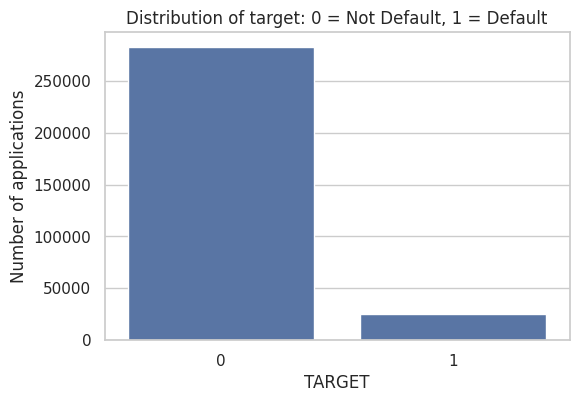

Default rate: 8.07%


In [13]:
if "TARGET" not in app_train.columns:
    raise KeyError("TARGET column was not found in application_train.csv")

display(app_train["TARGET"].value_counts(dropna=False).rename("count").to_frame())
target_pct = app_train["TARGET"].value_counts(normalize=True).mul(100).sort_index()
display(target_pct.rename("percentage").to_frame())

plt.figure(figsize=(6, 4))
sns.countplot(data=app_train, x="TARGET")
plt.title("Distribution of target: 0 = Not Default, 1 = Default")
plt.xlabel("TARGET")
plt.ylabel("Number of applications")
plt.show()

print(f"Default rate: {app_train['TARGET'].mean():.2%}")

## 6. Data cleaning and application-level feature engineering

The special `DAYS_EMPLOYED = 365243` value is treated as an anomalous placeholder and retained as a separate indicator. Ratio features use safe division to avoid infinite values.

In [14]:
# Work on a copy; remove exact duplicate application records if any.
app = app_train.copy()
before = len(app)
app = app.drop_duplicates()
print(f"Removed {before - len(app):,} duplicate application rows.")

# Handle known anomalous employment value.
if "DAYS_EMPLOYED" in app.columns:
    app["DAYS_EMPLOYED_ANOM"] = (app["DAYS_EMPLOYED"] == 365243).astype("int8")
    app.loc[app["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan

# XNA values are treated as missing, not as a separate meaningful category.
for col in ["CODE_GENDER", "ORGANIZATION_TYPE"]:
    if col in app.columns:
        app[col] = app[col].replace("XNA", np.nan)

# Convert negative day counts to years for interpretability.
day_to_year = {
    "DAYS_BIRTH": "AGE_YEARS",
    "DAYS_EMPLOYED": "YEARS_EMPLOYED",
    "DAYS_REGISTRATION": "YEARS_REGISTRATION",
    "DAYS_ID_PUBLISH": "YEARS_ID_PUBLISH"
}
for source, destination in day_to_year.items():
    if source in app.columns:
        app[destination] = -app[source] / 365.25

def safe_divide(numerator, denominator):
    denominator = denominator.replace(0, np.nan) if isinstance(denominator, pd.Series) else denominator
    return numerator / denominator

# Financial and household ratios.
if {"AMT_CREDIT", "AMT_INCOME_TOTAL"}.issubset(app.columns):
    app["CREDIT_INCOME_RATIO"] = safe_divide(app["AMT_CREDIT"], app["AMT_INCOME_TOTAL"])
if {"AMT_ANNUITY", "AMT_INCOME_TOTAL"}.issubset(app.columns):
    app["ANNUITY_INCOME_RATIO"] = safe_divide(app["AMT_ANNUITY"], app["AMT_INCOME_TOTAL"])
if {"AMT_ANNUITY", "AMT_CREDIT"}.issubset(app.columns):
    app["ANNUITY_CREDIT_RATIO"] = safe_divide(app["AMT_ANNUITY"], app["AMT_CREDIT"])
if {"AMT_GOODS_PRICE", "AMT_CREDIT"}.issubset(app.columns):
    app["GOODS_CREDIT_RATIO"] = safe_divide(app["AMT_GOODS_PRICE"], app["AMT_CREDIT"])
if {"YEARS_EMPLOYED", "AGE_YEARS"}.issubset(app.columns):
    app["EMPLOYED_AGE_RATIO"] = safe_divide(app["YEARS_EMPLOYED"], app["AGE_YEARS"])
if {"AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS"}.issubset(app.columns):
    app["INCOME_PER_PERSON"] = safe_divide(app["AMT_INCOME_TOTAL"], app["CNT_FAM_MEMBERS"])

ext_cols = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in app.columns]
if ext_cols:
    app["EXT_SOURCE_MEAN"] = app[ext_cols].mean(axis=1)
    app["EXT_SOURCE_MIN"] = app[ext_cols].min(axis=1)
    app["EXT_SOURCE_MAX"] = app[ext_cols].max(axis=1)

print("Application data after cleaning and feature engineering:", app.shape)

Removed 0 duplicate application rows.
Application data after cleaning and feature engineering: (307511, 136)


## 7. Exploratory data analysis (EDA)



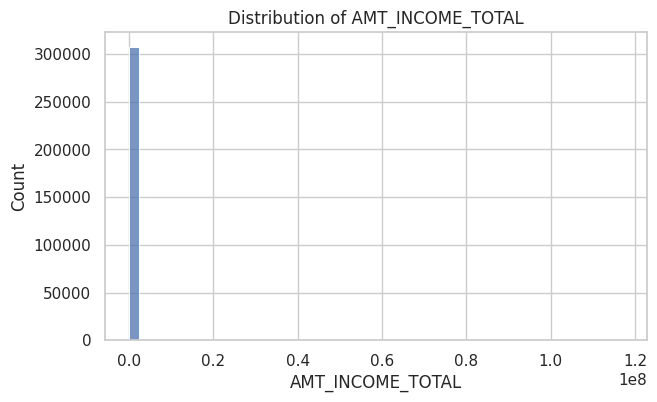

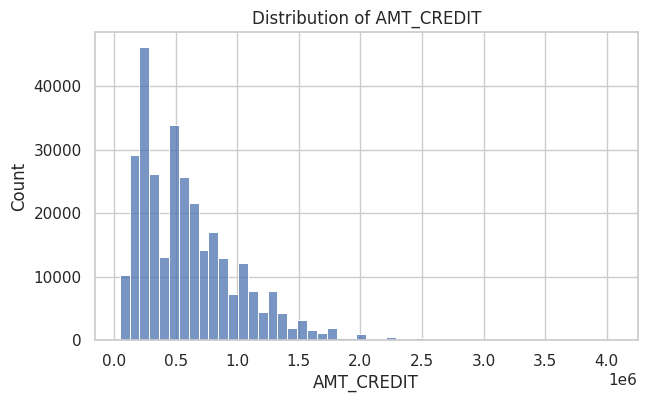

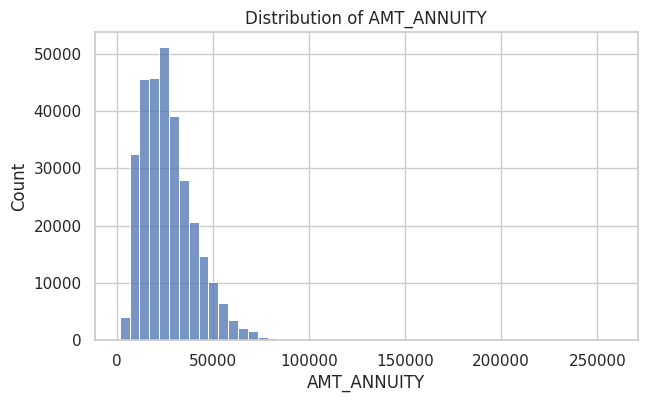

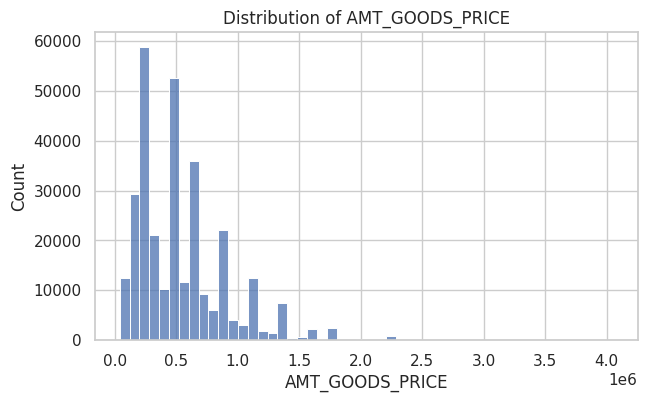

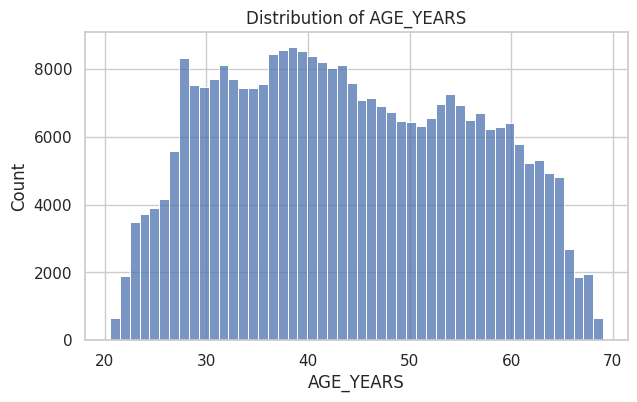

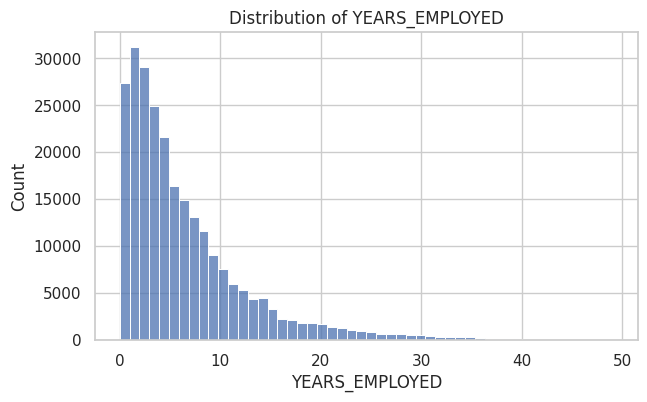

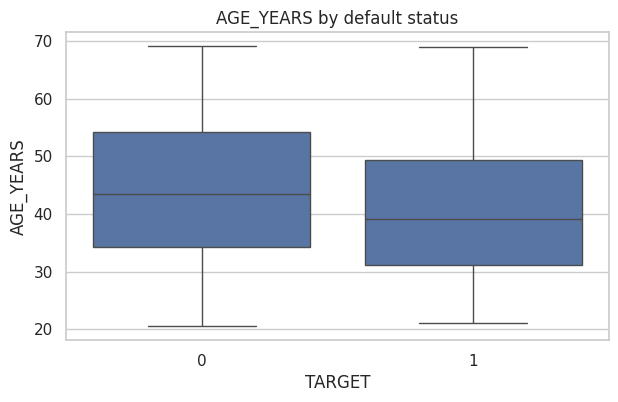

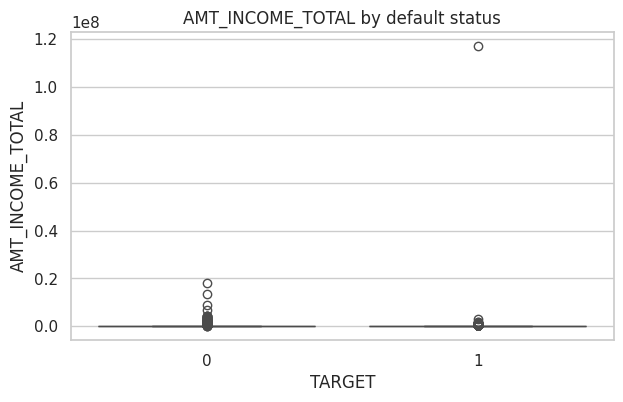

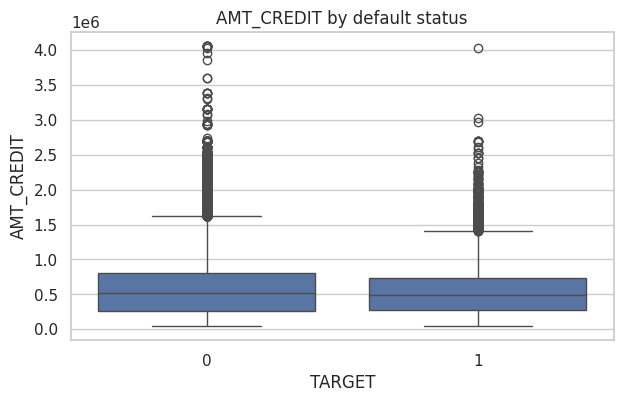

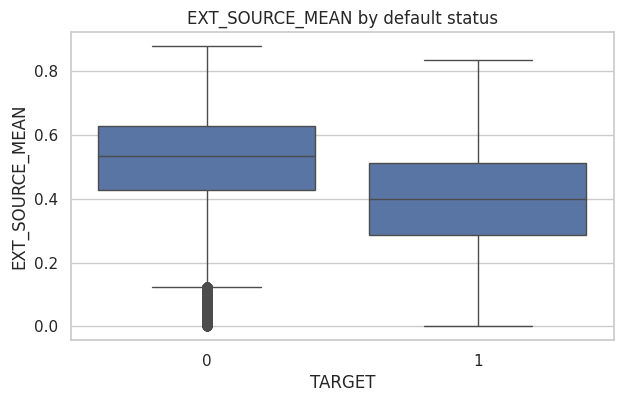

In [15]:
numeric_eda_cols = [
    c for c in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
                "AMT_GOODS_PRICE", "AGE_YEARS", "YEARS_EMPLOYED"]
    if c in app.columns
]

for col in numeric_eda_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=app, x=col, bins=50, kde=False)
    plt.title(f"Distribution of {col}")
    plt.show()

for col in [c for c in ["AGE_YEARS", "AMT_INCOME_TOTAL", "AMT_CREDIT",
                         "EXT_SOURCE_MEAN"] if c in app.columns]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=app, x="TARGET", y=col)
    plt.title(f"{col} by default status")
    plt.show()

### 7.2 Categorical default rates

.

,count,default_rate_percent
NAME_CONTRACT_TYPE,,
Revolving loans,29279,5.478329
Cash loans,278232,8.345913


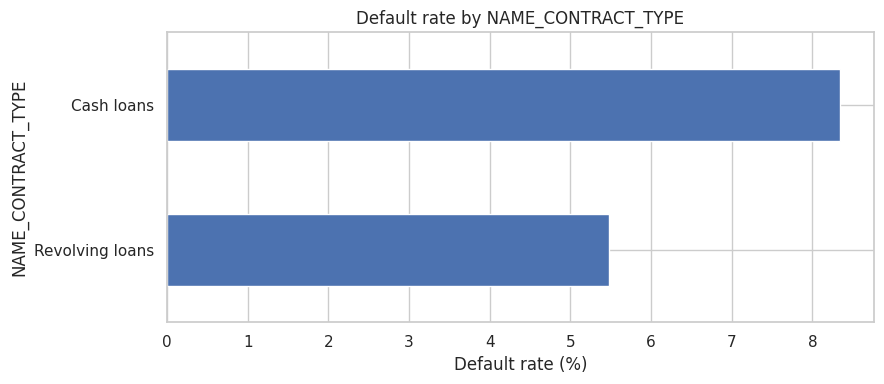

,count,default_rate_percent
CODE_GENDER,,
NaN,4,0.000000
F,202448,6.999328
M,105059,10.141920


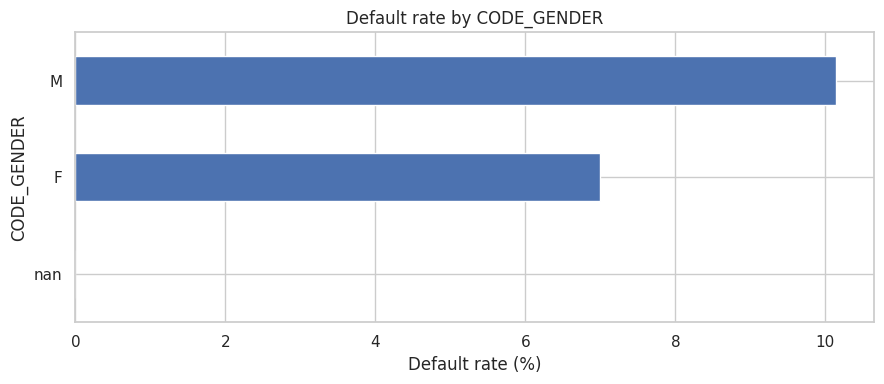

,count,default_rate_percent
NAME_EDUCATION_TYPE,,
Academic degree,164,1.829268
Higher education,74863,5.355115
Incomplete higher,10277,8.484966
Secondary / secondary special,218391,8.939929
Lower secondary,3816,10.927673


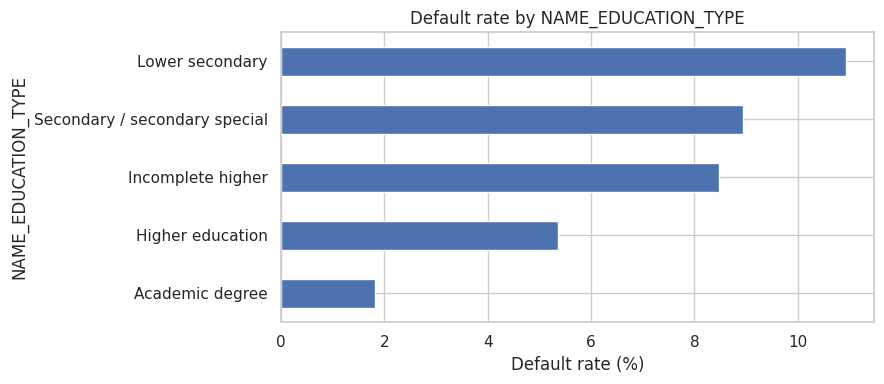

,count,default_rate_percent
NAME_INCOME_TYPE,,
Businessman,10,0.000000
Student,18,0.000000
Pensioner,55362,5.386366
State servant,21703,5.754965
Commercial associate,71617,7.484257
Working,158774,9.588472
Unemployed,22,36.363636
Maternity leave,5,40.000000


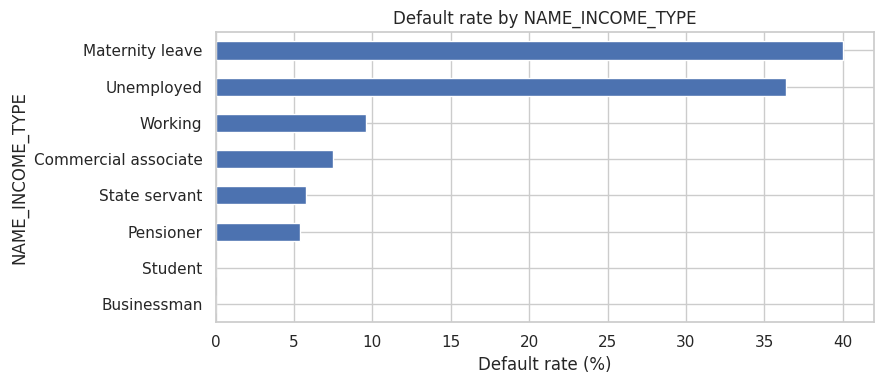

,count,default_rate_percent
OCCUPATION_TYPE,,
Accountants,9813,4.830327
High skill tech staff,11380,6.159930
Managers,21371,6.214028
Core staff,27570,6.303954
HR staff,563,6.394316
IT staff,526,6.463878
NaN,96391,6.513056
Private service staff,2652,6.598793
Medicine staff,8537,6.700246


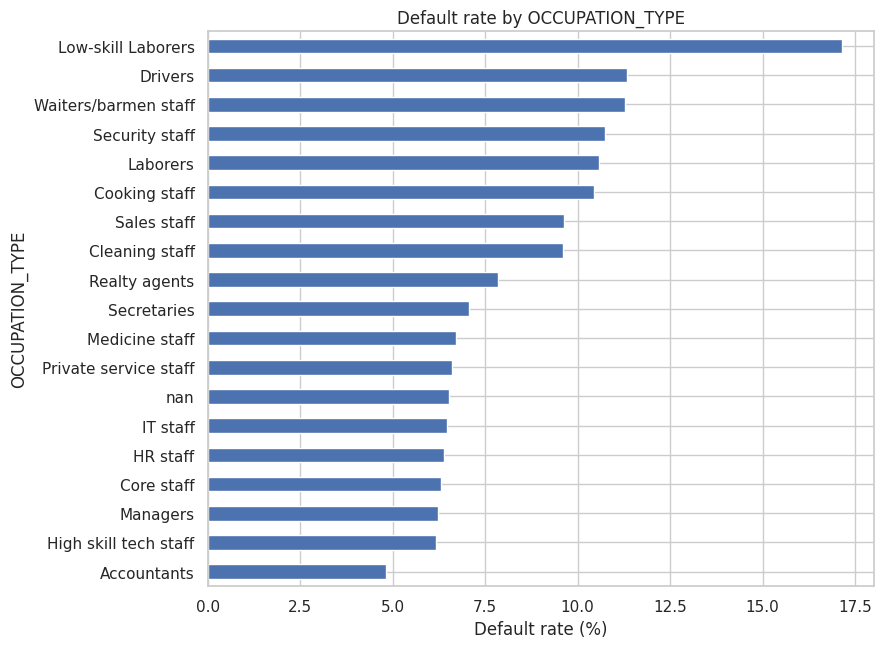

,count,default_rate_percent
NAME_FAMILY_STATUS,,
Unknown,2,0.000000
Widow,16088,5.824217
Married,196432,7.559868
Separated,19770,8.194234
Single / not married,45444,9.807675
Civil marriage,29775,9.944584


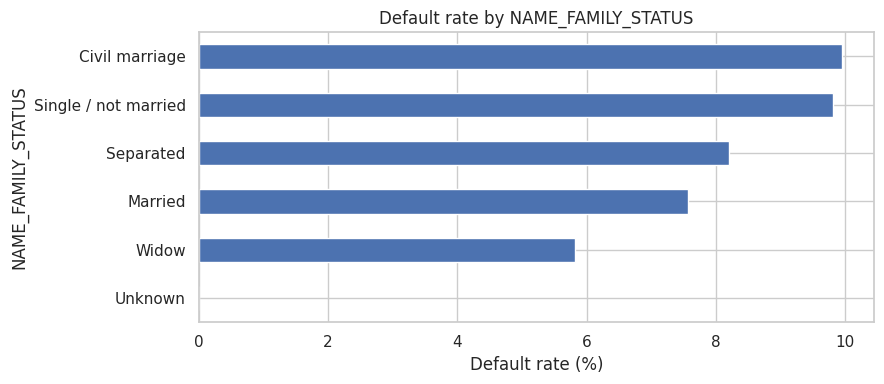

,count,default_rate_percent
NAME_HOUSING_TYPE,,
Office apartment,2617,6.572411
House / apartment,272868,7.795711
Co-op apartment,1122,7.932264
Municipal apartment,11183,8.539748
With parents,14840,11.698113
Rented apartment,4881,12.313051


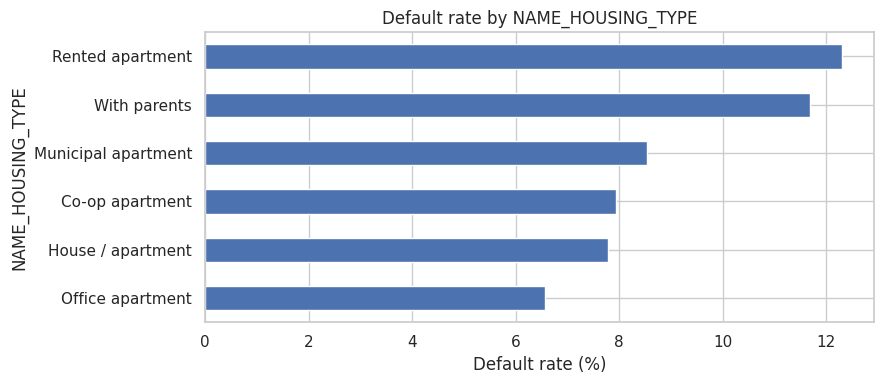

In [16]:
categorical_eda_cols = [
    c for c in ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_EDUCATION_TYPE",
                "NAME_INCOME_TYPE", "OCCUPATION_TYPE", "NAME_FAMILY_STATUS",
                "NAME_HOUSING_TYPE"] if c in app.columns
]

for col in categorical_eda_cols:
    rates = app.groupby(col, dropna=False)["TARGET"].agg(["mean", "count"])
    rates["default_rate_percent"] = rates["mean"] * 100
    rates = rates.sort_values("default_rate_percent")
    display(rates[["count", "default_rate_percent"]])
    plt.figure(figsize=(9, max(4, 0.35 * len(rates))))
    rates["default_rate_percent"].plot(kind="barh")
    plt.title(f"Default rate by {col}")
    plt.xlabel("Default rate (%)")
    plt.tight_layout()
    plt.show()

### 7.3 Numeric correlations with the target



Most negative correlations:


,correlation
EXT_SOURCE_MEAN,-0.222052
EXT_SOURCE_MAX,-0.196876
EXT_SOURCE_MIN,-0.185266
EXT_SOURCE_3,-0.178919
EXT_SOURCE_2,-0.160472
EXT_SOURCE_1,-0.155317
AGE_YEARS,-0.078239
YEARS_EMPLOYED,-0.074958
EMPLOYED_AGE_RATIO,-0.067955
GOODS_CREDIT_RATIO,-0.065407


Most positive correlations:


,correlation
DAYS_BIRTH,0.078239
DAYS_EMPLOYED,0.074958
REGION_RATING_CLIENT_W_CITY,0.060893
REGION_RATING_CLIENT,0.058899
DAYS_LAST_PHONE_CHANGE,0.055218
DAYS_ID_PUBLISH,0.051457
REG_CITY_NOT_WORK_CITY,0.050994
FLAG_EMP_PHONE,0.045982
REG_CITY_NOT_LIVE_CITY,0.044395
FLAG_DOCUMENT_3,0.044346


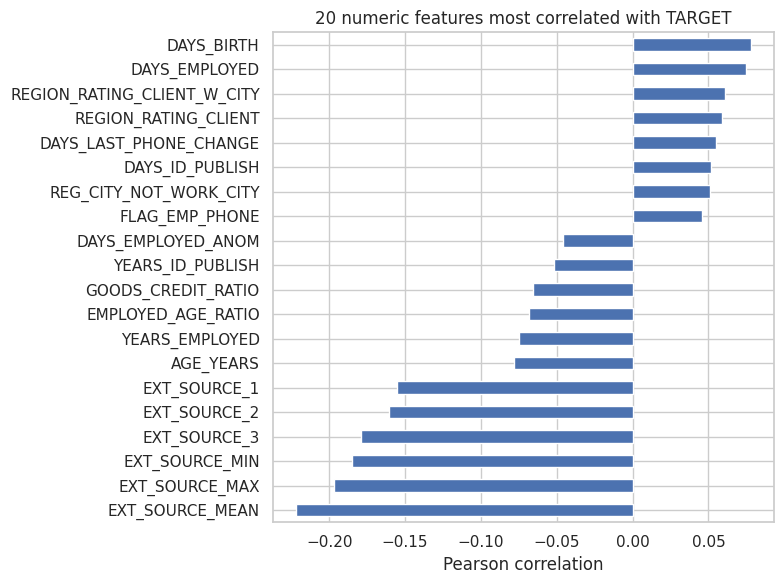

In [18]:
numeric_app = app.select_dtypes(include=np.number)
target_corr = numeric_app.corr()["TARGET"].drop("TARGET").sort_values()
print("Most negative correlations:")
display(target_corr.head(15).to_frame("correlation"))
print("Most positive correlations:")
display(target_corr.tail(15).sort_values(ascending=False).to_frame("correlation"))

plt.figure(figsize=(8, 6))
target_corr.reindex(target_corr.abs().sort_values(ascending=False).head(20).index).sort_values().plot(kind="barh")
plt.title("20 numeric features most correlated with TARGET")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

## 8. Aggregate historical datasets and merge to the application table

The case study describes one-to-many relationships:


In [17]:
def flatten_agg_columns(df, prefix):
    df = df.copy()
    df.columns = [
        prefix + "_" + "_".join([str(x) for x in col if str(x) != ""]).upper()
        if isinstance(col, tuple) else prefix + "_" + str(col).upper()
        for col in df.columns
    ]
    return df.reset_index()

# 8.1 Bureau balance: aggregate monthly history per bureau credit.
bb_agg = bureau_bal.groupby("SK_ID_BUREAU").agg(
    BB_MONTHS_MIN=("MONTHS_BALANCE", "min"),
    BB_MONTHS_MAX=("MONTHS_BALANCE", "max"),
    BB_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
    BB_STATUS_NUNIQUE=("STATUS", "nunique")
).reset_index()

# Join bureau-balance summaries to bureau records, then aggregate per customer.
bureau_with_bb = bureau.merge(bb_agg, on="SK_ID_BUREAU", how="left")
bureau_bb_customer = bureau_with_bb.groupby("SK_ID_CURR").agg(
    BUREAU_BB_MONTHS_MIN_MEAN=("BB_MONTHS_MIN", "mean"),
    BUREAU_BB_MONTHS_MAX_MEAN=("BB_MONTHS_MAX", "mean"),
    BUREAU_BB_MONTHS_COUNT_MEAN=("BB_MONTHS_COUNT", "mean"),
    BUREAU_BB_STATUS_NUNIQUE_MEAN=("BB_STATUS_NUNIQUE", "mean")
).reset_index()

# 8.2 Bureau summary per customer.
bureau_customer = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_CREDIT_COUNT=("SK_ID_BUREAU", "count"),
    BUREAU_DAYS_CREDIT_MEAN=("DAYS_CREDIT", "mean"),
    BUREAU_DAYS_CREDIT_MIN=("DAYS_CREDIT", "min"),
    BUREAU_DAYS_CREDIT_MAX=("DAYS_CREDIT", "max"),
    BUREAU_CREDIT_SUM_MEAN=("AMT_CREDIT_SUM", "mean"),
    BUREAU_CREDIT_SUM_TOTAL=("AMT_CREDIT_SUM", "sum"),
    BUREAU_DEBT_MEAN=("AMT_CREDIT_SUM_DEBT", "mean"),
    BUREAU_DEBT_TOTAL=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_OVERDUE_MEAN=("AMT_CREDIT_SUM_OVERDUE", "mean"),
    BUREAU_OVERDUE_TOTAL=("AMT_CREDIT_SUM_OVERDUE", "sum")
).reset_index()

# 8.3 POS/CASH monthly history.
pos_customer = pos_cash.groupby("SK_ID_CURR").agg(
    POS_RECORD_COUNT=("SK_ID_PREV", "count"),
    POS_MONTHS_BALANCE_MEAN=("MONTHS_BALANCE", "mean"),
    POS_MONTHS_BALANCE_MAX=("MONTHS_BALANCE", "max"),
    POS_INSTALMENT_MEAN=("CNT_INSTALMENT", "mean"),
    POS_INSTALMENT_FUTURE_MEAN=("CNT_INSTALMENT_FUTURE", "mean"),
    POS_LATE_PAYMENT_MEAN=("SK_DPD", "mean"),
    POS_LATE_PAYMENT_DEF_MEAN=("SK_DPD_DEF", "mean")
).reset_index()

# 8.4 Credit-card monthly history.
credit_card = credit_card.copy()
credit_card["CC_UTILIZATION"] = np.where(
    credit_card["AMT_CREDIT_LIMIT_ACTUAL"] > 0,
    credit_card["AMT_BALANCE"] / credit_card["AMT_CREDIT_LIMIT_ACTUAL"],
    np.nan
)
cc_customer = credit_card.groupby("SK_ID_CURR").agg(
    CC_RECORD_COUNT=("SK_ID_PREV", "count"),
    CC_BALANCE_MEAN=("AMT_BALANCE", "mean"),
    CC_BALANCE_MAX=("AMT_BALANCE", "max"),
    CC_CREDIT_LIMIT_MEAN=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
    CC_DRAWINGS_MEAN=("AMT_DRAWINGS_CURRENT", "mean"),
    CC_PAYMENT_MEAN=("AMT_PAYMENT_TOTAL_CURRENT", "mean"),
    CC_UTILIZATION_MEAN=("CC_UTILIZATION", "mean")
).reset_index()

# 8.5 Previous applications.
previous_customer = previous.groupby("SK_ID_CURR").agg(
    PREV_APPLICATION_COUNT=("SK_ID_PREV", "count"),
    PREV_APPLICATION_AMOUNT_MEAN=("AMT_APPLICATION", "mean"),
    PREV_APPLICATION_AMOUNT_SUM=("AMT_APPLICATION", "sum"),
    PREV_CREDIT_AMOUNT_MEAN=("AMT_CREDIT", "mean"),
    PREV_CREDIT_AMOUNT_SUM=("AMT_CREDIT", "sum"),
    PREV_ANNUITY_MEAN=("AMT_ANNUITY", "mean"),
    PREV_DAYS_DECISION_MEAN=("DAYS_DECISION", "mean"),
    PREV_DAYS_DECISION_MAX=("DAYS_DECISION", "max")
).reset_index()

# 8.6 Installment repayment history.
installments = installments.copy()
installments["PAYMENT_DIFFERENCE"] = (
    installments["AMT_PAYMENT"] - installments["AMT_INSTALMENT"]
)
installments["PAYMENT_DELAY_DAYS"] = (
    installments["DAYS_ENTRY_PAYMENT"] - installments["DAYS_INSTALMENT"]
)

installment_customer = installments.groupby("SK_ID_CURR").agg(
    INST_PAYMENT_RECORD_COUNT=("SK_ID_PREV", "count"),
    INST_PAYMENT_MEAN=("AMT_PAYMENT", "mean"),
    INST_PAYMENT_SUM=("AMT_PAYMENT", "sum"),
    INST_AMOUNT_MEAN=("AMT_INSTALMENT", "mean"),
    INST_AMOUNT_SUM=("AMT_INSTALMENT", "sum"),
    INST_PAYMENT_DIFFERENCE_MEAN=("PAYMENT_DIFFERENCE", "mean"),
    INST_PAYMENT_DELAY_MEAN=("PAYMENT_DELAY_DAYS", "mean"),
    INST_PAYMENT_DELAY_MAX=("PAYMENT_DELAY_DAYS", "max")
).reset_index()

print("Aggregated table shapes:")
for name, frame in {
    "bureau balance": bureau_bb_customer,
    "bureau": bureau_customer,
    "POS/CASH": pos_customer,
    "credit card": cc_customer,
    "previous applications": previous_customer,
    "installments": installment_customer
}.items():
    print(f"{name:22s}: {frame.shape}")

Aggregated table shapes:
bureau balance        : (305811, 5)
bureau                : (305811, 11)
POS/CASH              : (337252, 8)
credit card           : (103558, 8)
previous applications : (338857, 9)
installments          : (339587, 9)


In [19]:
# Merge one-row-per-customer summaries into the main application table.
model_data = app.copy()

aggregates = [
    bureau_customer,
    bureau_bb_customer,
    pos_customer,
    cc_customer,
    previous_customer,
    installment_customer
]

for agg in aggregates:
    if agg["SK_ID_CURR"].duplicated().any():
        raise ValueError("An aggregate table contains duplicate SK_ID_CURR values.")
    model_data = model_data.merge(agg, on="SK_ID_CURR", how="left", validate="one_to_one")

print("Merged modelling table:", model_data.shape)
print("Application rows preserved:", len(model_data) == len(app))
print("Duplicate customer IDs:", model_data["SK_ID_CURR"].duplicated().sum())
display(model_data.head())

Merged modelling table: (307511, 180)
Application rows preserved: True
Duplicate customer IDs: 0


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,...,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_ANOM,AGE_YEARS,YEARS_EMPLOYED,YEARS_REGISTRATION,YEARS_ID_PUBLISH,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,ANNUITY_CREDIT_RATIO,GOODS_CREDIT_RATIO,EMPLOYED_AGE_RATIO,INCOME_PER_PERSON,EXT_SOURCE_MEAN,EXT_SOURCE_MIN,EXT_SOURCE_MAX,BUREAU_CREDIT_COUNT,BUREAU_DAYS_CREDIT_MEAN,BUREAU_DAYS_CREDIT_MIN,BUREAU_DAYS_CREDIT_MAX,BUREAU_CREDIT_SUM_MEAN,BUREAU_CREDIT_SUM_TOTAL,BUREAU_DEBT_MEAN,BUREAU_DEBT_TOTAL,BUREAU_OVERDUE_MEAN,BUREAU_OVERDUE_TOTAL,BUREAU_BB_MONTHS_MIN_MEAN,BUREAU_BB_MONTHS_MAX_MEAN,BUREAU_BB_MONTHS_COUNT_MEAN,BUREAU_BB_STATUS_NUNIQUE_MEAN,POS_RECORD_COUNT,POS_MONTHS_BALANCE_MEAN,POS_MONTHS_BALANCE_MAX,POS_INSTALMENT_MEAN,POS_INSTALMENT_FUTURE_MEAN,POS_LATE_PAYMENT_MEAN,POS_LATE_PAYMENT_DEF_MEAN,CC_RECORD_COUNT,CC_BALANCE_MEAN,CC_BALANCE_MAX,CC_CREDIT_LIMIT_MEAN,CC_DRAWINGS_MEAN,CC_PAYMENT_MEAN,CC_UTILIZATION_MEAN,PREV_APPLICATION_COUNT,PREV_APPLICATION_AMOUNT_MEAN,PREV_APPLICATION_AMOUNT_SUM,PREV_CREDIT_AMOUNT_MEAN,PREV_CREDIT_AMOUNT_SUM,PREV_ANNUITY_MEAN,PREV_DAYS_DECISION_MEAN,PREV_DAYS_DECISION_MAX,INST_PAYMENT_RECORD_COUNT,INST_PAYMENT_MEAN,INST_PAYMENT_SUM,INST_AMOUNT_MEAN,INST_AMOUNT_SUM,INST_PAYMENT_DIFFERENCE_MEAN,INST_PAYMENT_DELAY_MEAN,INST_PAYMENT_DELAY_MAX
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637.0,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,...,0.0,1.0,0,25.902806,1.744011,9.987680,5.804244,2.007889,0.121978,0.060749,0.863262,0.067329,202500.0,0.161787,0.083037,0.262949,8.0,-874.00,-1437.0,-103.0,108131.945625,865055.565,49156.2,245781.0,0.0,0.0,-28.25,-15.5,13.75,3.25,19.0,-10.000000,-1.0,24.000000,15.000000,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,179055.00,179055.00,179055.00,179055.0,9251.775,-606.000000,-606.0,19.0,11559.247105,219625.695,11559.247105,219625.695,0.000000,-20.421053,-12.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188.0,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,...,0.0,0.0,0,45.900068,3.252567,3.247091,0.796715,4.790750,0.132217,0.027598,0.873211,0.070862,135000.0,0.466757,0.311267,0.622246,4.0,-1400.75,-2586.0,-606.0,254350.125000,1017400.500,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,28.0,-43.785714,-18.0,10.107143,5.785714,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,435436.50,1306309.50,484191.00,1452573.0,56553.990,-1305.000000,-746.0,25.0,64754.586000,1618864.650,64754.586000,1618864.650,0.000000,-7.160000,-1.0
2,100004,0,Revolving 

## 9. Prepare modelling data and create train/validation/test sets



In [20]:
X = model_data.drop(columns=["TARGET", "SK_ID_CURR"])
y = model_data["TARGET"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

for label, features, target in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(f"{label:10s} X={features.shape}, y={target.shape}, default rate={target.mean():.4f}")

Train      X=(215257, 178), y=(215257,), default rate=0.0807
Validation X=(46127, 178), y=(46127,), default rate=0.0807
Test       X=(46127, 178), y=(46127,), default rate=0.0807


## 10. Preprocessing pipeline

The preprocessing is fitted only on training data:
- Numeric columns: median imputation and standard scaling.
- Categorical columns: most-frequent imputation and one-hot encoding.
- Unseen categories in validation/test data are ignored safely.

Using a pipeline ensures the same transformations are applied consistently and avoids leakage from validation/test data.

In [21]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 162
Categorical features: 16


## 11. Build and compare multiple classification models



In [22]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        C=0.1,
        solver="liblinear",
        random_state=45
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        max_depth=14,
        min_samples_leaf=30,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=45
    )

}


try:
    from xgboost import XGBClassifier
    neg = int((y_train == 0).sum())
    pos = int((y_train == 1).sum())
    models["XGBoost"] = XGBClassifier(
        n_estimators=350, max_depth=5, learning_rate=0.04,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=neg / max(pos, 1),
        eval_metric="auc", n_jobs=-1,
        random_state=45
    )
except ImportError:
    print("XGBoost not installed; skipping XGBoost.")

try:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(
        n_estimators=450, learning_rate=0.04, num_leaves=31,
        class_weight="balanced", subsample=0.8,
        colsample_bytree=0.8, n_jobs=-1,
        random_state=45, verbosity=-1
    )
except ImportError:
    print("LightGBM not installed; skipping LightGBM.")

print("Models:", list(models))

Models: ['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM']


In [23]:
fitted_models = {}
validation_probabilities = {}
comparison_rows = []

for model_name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    start = time.time()
    pipeline.fit(X_train, y_train)
    fit_seconds = time.time() - start

    val_probability = pipeline.predict_proba(X_val)[:, 1]
    val_prediction_05 = (val_probability >= 0.5).astype(int)

    fitted_models[model_name] = pipeline
    validation_probabilities[model_name] = val_probability

    comparison_rows.append({
        "Model": model_name,
        "Validation ROC-AUC": roc_auc_score(y_val, val_probability),
        "Validation PR-AUC": average_precision_score(y_val, val_probability),
        "Validation Precision": precision_score(y_val, val_prediction_05, zero_division=0),
        "Validation Recall": recall_score(y_val, val_prediction_05, zero_division=0),
        "Validation F1": f1_score(y_val, val_prediction_05, zero_division=0),
        "Training time (seconds)": fit_seconds
    })
    print(f"{model_name}: fitted in {fit_seconds:.1f} seconds")

comparison = pd.DataFrame(comparison_rows).sort_values(
    "Validation ROC-AUC", ascending=False
).reset_index(drop=True)

display(comparison.round(4))

Logistic Regression: fitted in 108.6 seconds
Random Forest: fitted in 382.8 seconds
XGBoost: fitted in 81.9 seconds
LightGBM: fitted in 82.3 seconds


,Model,Validation ROC-AUC,Validation PR-AUC,Validation Precision@0.5,Validation Recall@0.5,Validation F1@0.5,Training time (seconds)
0,LightGBM,0.7826,0.2764,0.1907,0.6767,0.2975,82.2874
1,XGBoost,0.7810,0.2742,0.1873,0.6839,0.2940,81.8987
2,Logistic Regression,0.7624,0.2489,0.1683,0.6882,0.2704,108.5619
3,Random Forest,0.7614,0.2455,0.2053,0.5325,0.2964,382.8288


## 12. Select the model and tune the classification threshold on validation data



In [24]:
best_name = comparison.loc[0, "Model"]
best_model = fitted_models[best_name]
val_proba = validation_probabilities[best_name]

precision_values, recall_values, thresholds = precision_recall_curve(y_val, val_proba)

# precision_recall_curve returns one more precision/recall point than thresholds.
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-12)
)

best_threshold_index = int(np.nanargmax(f1_values))
best_threshold = float(thresholds[best_threshold_index])

print("Selected model:", best_name)
print("Threshold selected on validation data:", round(best_threshold, 4))
print("Best validation F1:", round(float(f1_values[best_threshold_index]), 4))

Selected model: LightGBM
Threshold selected on validation data: 0.6726
Best validation F1: 0.3336


## 13. Final evaluation on the untouched test set



,Model,Threshold,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC
0,LightGBM,0.6726,0.8626,0.2727,0.4213,0.3311,0.7852,0.2763


Classification report:
                 precision    recall  f1-score   support

Not Default (0)       0.95      0.90      0.92     42403
    Default (1)       0.27      0.42      0.33      3724

       accuracy                           0.86     46127
      macro avg       0.61      0.66      0.63     46127
   weighted avg       0.89      0.86      0.88     46127



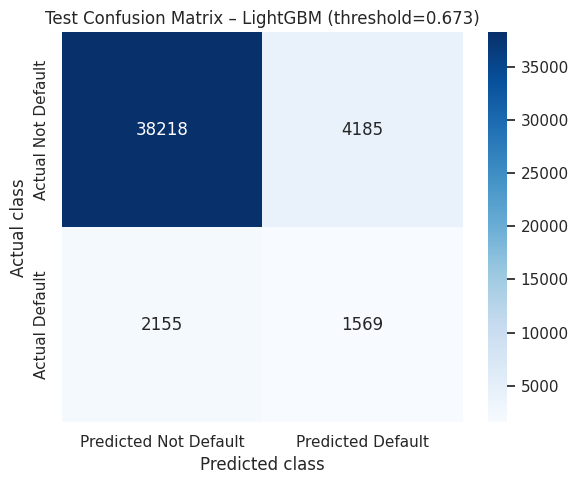

In [25]:
test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

final_metrics = {
    "Model": best_name,
    "Threshold": best_threshold,
    "Test Accuracy": accuracy_score(y_test, test_pred),
    "Test Precision": precision_score(y_test, test_pred, zero_division=0),
    "Test Recall": recall_score(y_test, test_pred, zero_division=0),
    "Test F1": f1_score(y_test, test_pred, zero_division=0),
    "Test ROC-AUC": roc_auc_score(y_test, test_proba),
    "Test PR-AUC": average_precision_score(y_test, test_proba)
}
display(pd.DataFrame([final_metrics]).round(4))

print("Classification report:")
print(classification_report(
    y_test, test_pred,
    target_names=["Not Default (0)", "Default (1)"],
    zero_division=0
))

cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted Not Default", "Predicted Default"],
    yticklabels=["Actual Not Default", "Actual Default"]
)
plt.title(f"Test Confusion Matrix – {best_name} (threshold={best_threshold:.3f})")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()

## 14. Precision-recall curve and ROC curve



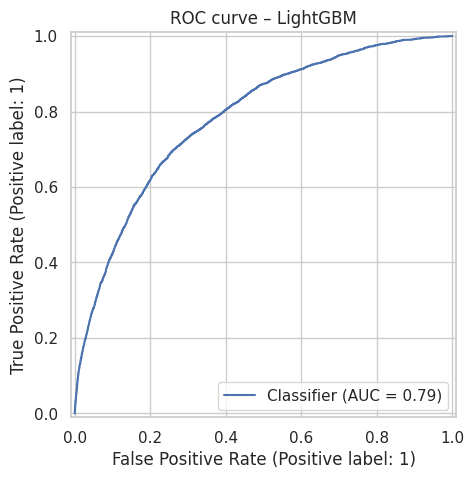

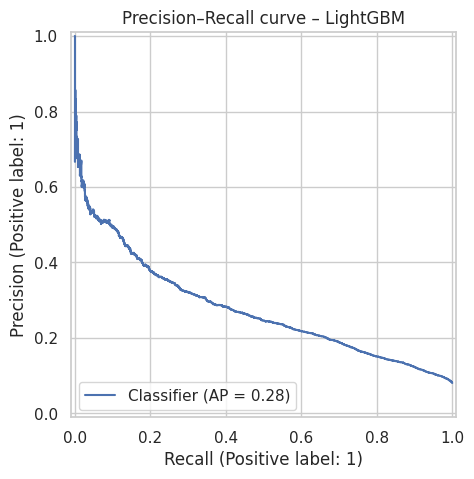

In [26]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, test_proba, ax=ax)
ax.set_title(f"ROC curve – {best_name}")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=ax)
ax.set_title(f"Precision–Recall curve – {best_name}")
plt.show()

## 15. Important features

Permutation importance is calculated on the validation set to avoid using the final test set for feature interpretation/model selection. Because the model is a pipeline, importance is reported for the original input columns.

,Feature,Importance mean,Importance std
131,EXT_SOURCE_MEAN,0.046562,0.003600
152,POS_INSTALMENT_FUTURE_MEAN,0.010515,0.002523
127,ANNUITY_CREDIT_RATIO,0.007181,0.002337
172,INST_PAYMENT_SUM,0.005955,0.000762
132,EXT_SOURCE_MIN,0.005171,0.000504
166,PREV_CREDIT_AMOUNT_SUM,0.003259,0.000303
11,NAME_EDUCATION_TYPE,0.003149,0.000176
161,CC_UTILIZATION_MEAN,0.002726,0.001499
8,AMT_GOODS_PRICE,0.002685,0.001159
41,EXT_SOURCE_3,0.002268,0.000200


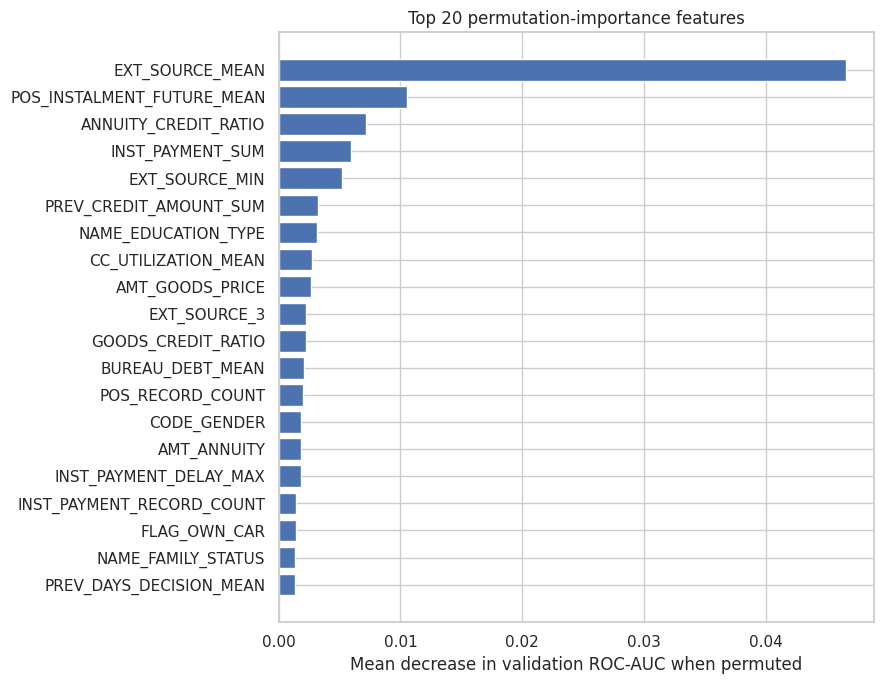

In [29]:
importance_sample = X_val.sample(n=min(5000, len(X_val)), random_state=45)
importance_labels = y_val.loc[importance_sample.index]

perm = permutation_importance(
    best_model,
    importance_sample,
    importance_labels,
    scoring="roc_auc",
    n_repeats=3,
    random_state=45,
    n_jobs=-1
)

importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance mean": perm.importances_mean,
    "Importance std": perm.importances_std
}).sort_values("Importance mean", ascending=False)

display(importance.head(25))

top_importance = importance.head(20).sort_values("Importance mean")
plt.figure(figsize=(9, 7))
plt.barh(top_importance["Feature"], top_importance["Importance mean"])
plt.xlabel("Mean decrease in validation ROC-AUC when permuted")
plt.title("Top 20 permutation-importance features")
plt.tight_layout()
plt.show()

## 16. Customer-segment analysis



,applications,default_rate_percent
AGE_GROUP,,
<=25,12233,12.29
26-35,72429,10.66
36-45,84261,8.41
46-55,70190,7.05
56-65,60522,5.42
>65,7876,3.66


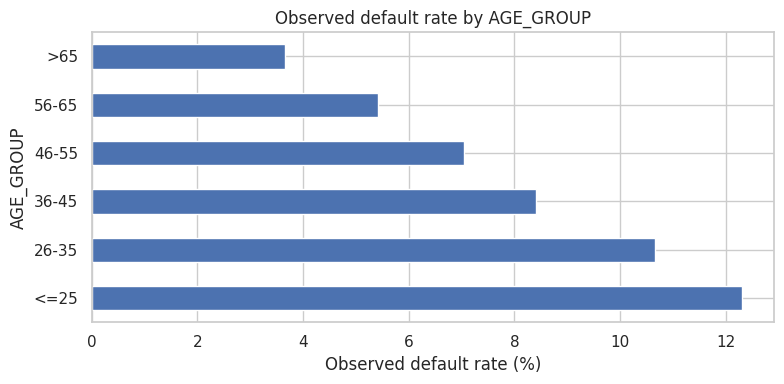

,applications,default_rate_percent
INCOME_BAND,,
"(25649.999, 99000.0]",63671,8.21
"(99000.0, 135000.0]",85756,8.59
"(135000.0, 162000.0]",35453,8.68
"(162000.0, 225000.0]",75513,8.06
"(225000.0, 117000000.0]",47118,6.52


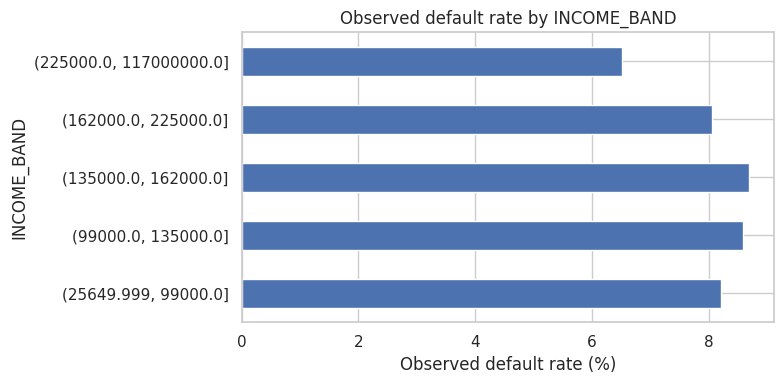

,applications,default_rate_percent
EXT_SOURCE_BAND,,
"(-0.00099406, 0.384]",61468,18.72
"(0.384, 0.484]",61468,9.31
"(0.484, 0.564]",61467,5.91
"(0.564, 0.644]",61468,3.95
"(0.644, 0.879]",61468,2.48
NaN,172,8.14


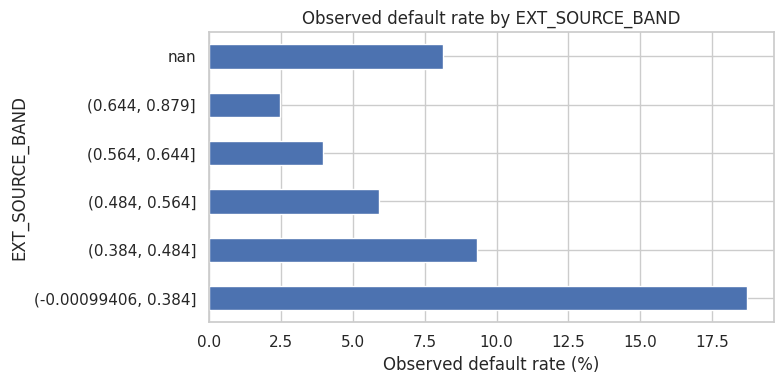

,applications,default_rate_percent
EMPLOYMENT_BAND,,
Not recorded/0,2,50.00
Under 1 year,27980,10.97
1-5 years,108374,10.47
5-10 years,64871,7.37
Over 10 years,50910,5.19
NaN,55374,5.40


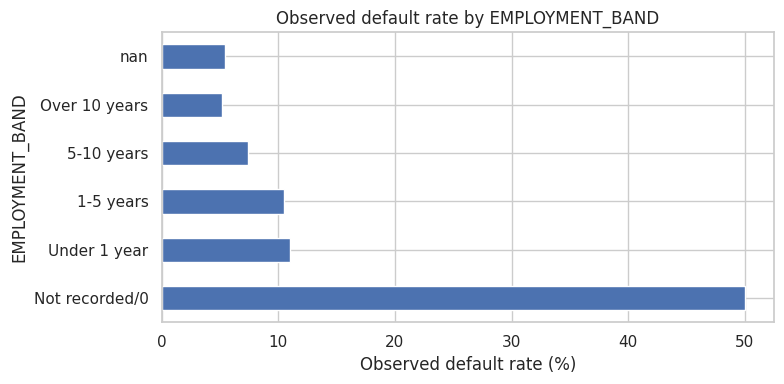

,applications,default_rate_percent
NAME_EDUCATION_TYPE,,
Academic degree,164,1.83
Higher education,74863,5.36
Incomplete higher,10277,8.48
Lower secondary,3816,10.93
Secondary / secondary special,218391,8.94


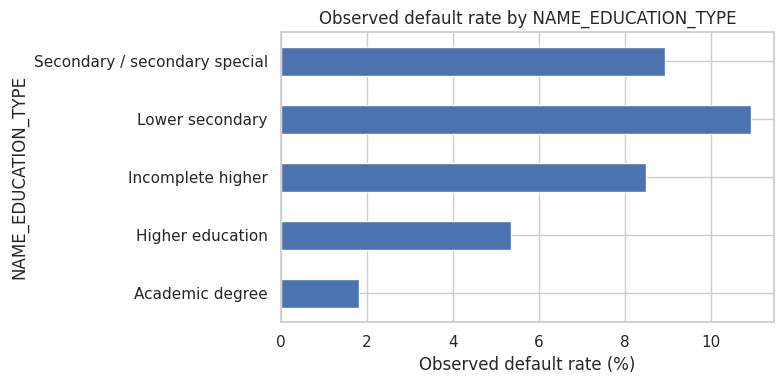

,applications,default_rate_percent
NAME_INCOME_TYPE,,
Businessman,10,0.00
Commercial associate,71617,7.48
Maternity leave,5,40.00
Pensioner,55362,5.39
State servant,21703,5.75
Student,18,0.00
Unemployed,22,36.36
Working,158774,9.59


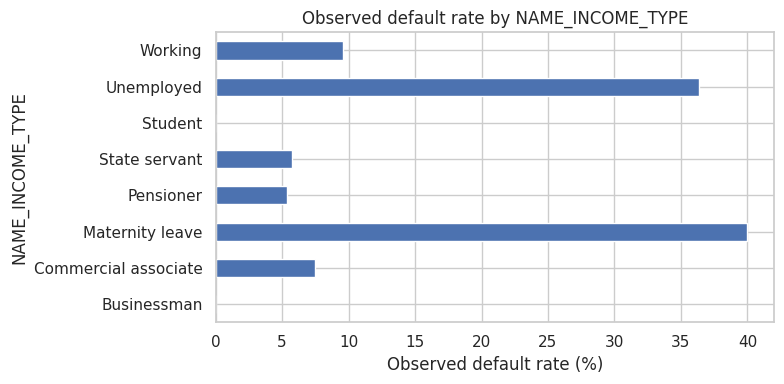

,applications,default_rate_percent
NAME_FAMILY_STATUS,,
Civil marriage,29775,9.94
Married,196432,7.56
Separated,19770,8.19
Single / not married,45444,9.81
Unknown,2,0.00
Widow,16088,5.82


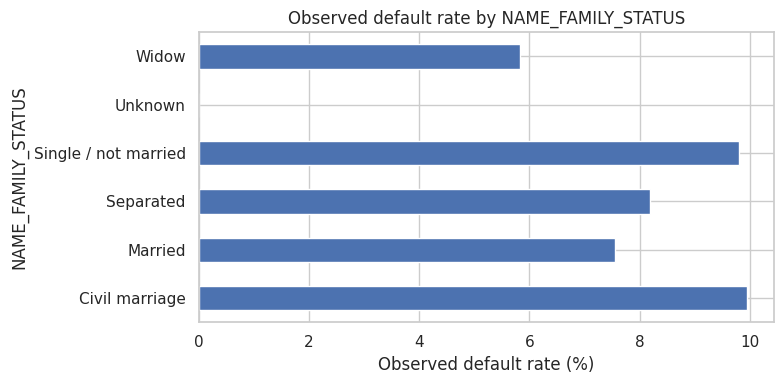

In [30]:
segments = app.copy()

if "AGE_YEARS" in segments.columns:
    segments["AGE_GROUP"] = pd.cut(
        segments["AGE_YEARS"],
        bins=[0, 25, 35, 45, 55, 65, 100],
        labels=["<=25", "26-35", "36-45", "46-55", "56-65", ">65"],
        include_lowest=True
    )

if "AMT_INCOME_TOTAL" in segments.columns:
    segments["INCOME_BAND"] = pd.qcut(
        segments["AMT_INCOME_TOTAL"],
        q=5, duplicates="drop"
    )

if "EXT_SOURCE_MEAN" in segments.columns:
    segments["EXT_SOURCE_BAND"] = pd.qcut(
        segments["EXT_SOURCE_MEAN"],
        q=5, duplicates="drop"
    )

if "YEARS_EMPLOYED" in segments.columns:
    segments["EMPLOYMENT_BAND"] = pd.cut(
        segments["YEARS_EMPLOYED"],
        bins=[-1, 0, 1, 5, 10, 100],
        labels=["Not recorded/0", "Under 1 year", "1-5 years", "5-10 years", "Over 10 years"]
    )

segment_columns = [
    c for c in ["AGE_GROUP", "INCOME_BAND", "EXT_SOURCE_BAND", "EMPLOYMENT_BAND",
                "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "NAME_FAMILY_STATUS"]
    if c in segments.columns
]

for col in segment_columns:
    summary = segments.groupby(col, observed=False, dropna=False)["TARGET"].agg(
        applications="count", default_rate="mean"
    )
    summary["default_rate_percent"] = summary["default_rate"] * 100
    display(summary[["applications", "default_rate_percent"]].round(2))

    plot_data = summary.dropna(subset=["default_rate_percent"])
    plt.figure(figsize=(8, max(4, 0.35 * len(plot_data))))
    plot_data["default_rate_percent"].plot(kind="barh")
    plt.xlabel("Observed default rate (%)")
    plt.title(f"Observed default rate by {col}")
    plt.tight_layout()
    plt.show()

##  Model comparison report

The comparison table above contains validation metrics for every model. The final selected model is evaluated once on the test set.

### Production recommendation
The model with the strongest validation ROC-AUC is selected in this notebook, then checked on the untouched test data. A production decision should also consider:
- PR-AUC and recall for the default class;
- the bank's cost of missed defaulters versus incorrectly flagged reliable applicants;
- calibration, fairness, explainability and stability over time;
- data privacy, governance, monitoring and human oversight.



##  Challenges faced and techniques used

| Challenge | Technique used | Reason |
|---|---|---|
| Different table granularities | Aggregate historical tables by `SK_ID_CURR`; aggregate `bureau_balance` by `SK_ID_BUREAU` first | Prevents row multiplication and preserves one application row per customer |
| Missing values | Median imputation for numeric features; most-frequent imputation for categorical features | Robust, simple baseline that is fitted on training data only |
| Special anomalous employment value | Create an anomaly indicator and replace the placeholder with missing | Retains information that the original value was anomalous |
| Categorical variables | One-hot encoding with unknown-category handling | Converts categories into model-ready features and handles unseen values |
| Different feature scales | Standard scaling for numeric pipeline | Helps Logistic Regression optimisation |
| Imbalanced target | Class weights and PR-AUC/recall/F1 reporting | Accuracy alone can hide poor detection of defaulters |
| Threshold choice | Select threshold using validation precision-recall curve | Avoids using test data to tune the classifier |
| Test-data leakage | Train/validation/test split and training-only preprocessing fit | Keeps final test metrics independent of model selection |
| Complex model interpretation | Permutation importance and segment default-rate analysis | Provides a more interpretable view of important signals and observed groups |

Add any additional issues you actually encountered while running the notebook, along with the exact resolution used.